In [1]:
# 1. Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

sns.set_theme(style='whitegrid')
np.random.seed(42)
print("comlpleted")

comlpleted


In [2]:
# 2.1 Load the raw nutrition dataset
df = pd.read_csv('../datasets/nutrition.csv')

print('Dataset Shape:', df.shape)
print('\nData Types:')
print(df.dtypes.value_counts())
print('\nMissing Values:')
print(df.isnull().sum())
print('\nDuplicate Rows:', df.duplicated().sum())
print('\nOriginal Target Distribution:')
print(df['category'].value_counts())

Dataset Shape: (1818, 24)

Data Types:
float64    22
str         2
Name: count, dtype: int64

Missing Values:
food_name          0
category           0
calories           0
protein_g          0
carbohydrates_g    0
fat_g              0
fiber_g            0
sugars_g           0
calcium_mg         0
iron_mg            0
sodium_mg          0
potassium_mg       0
magnesium_mg       0
phosphorus_mg      0
zinc_mg            0
vitamin_a_iu       0
vitamin_c_mg       0
vitamin_b1_mg      0
vitamin_b2_mg      0
vitamin_b3_mg      0
vitamin_b5_mg      0
vitamin_b6_mg      0
vitamin_e_mg       0
folate_mcg         0
dtype: int64

Duplicate Rows: 0

Original Target Distribution:
category
Indian Food             1014
Vegetable                160
Condiment                115
Fruit                     82
General                   66
Beverage                  52
Grain                     49
Meal/Processed            28
Protein/Meat              27
Dairy                     26
Dessert                 

Shape after duplicate removal: (1818, 25)

Classification Target Distribution:
category_group
Indian Food       1014
Other              199
Vegetable          160
Condiment          115
Fruit               82
General             66
Beverage            52
Grain               49
Meal/Processed      28
Protein/Meat        27
Dairy               26
Name: count, dtype: int64


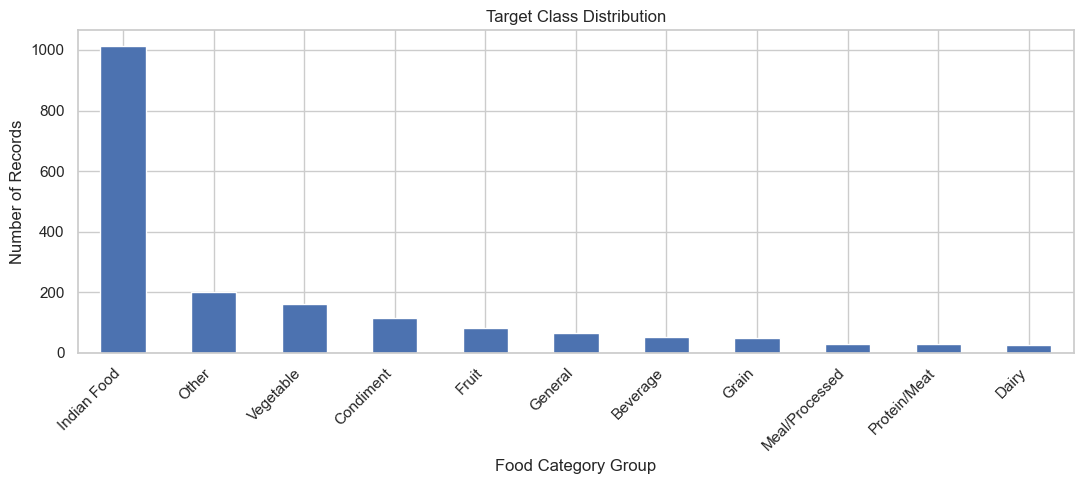

In [3]:
# 2.2 Remove duplicates and create the classification target
df = df.drop_duplicates().copy()

top_categories = df['category'].value_counts().head(10).index
df['category_group'] = df['category'].where(df['category'].isin(top_categories), 'Other')

print('Shape after duplicate removal:', df.shape)
print('\nClassification Target Distribution:')
print(df['category_group'].value_counts())

plt.figure(figsize=(11,5))
df['category_group'].value_counts().plot(kind='bar')
plt.xticks(rotation=45, ha='right')
plt.title('Target Class Distribution')
plt.xlabel('Food Category Group')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()

**Observation:** The original dataset contains many detailed food categories with very small class counts. Grouping the less frequent categories into **Other** reduces extremely small classes and makes stratified classification more reliable.

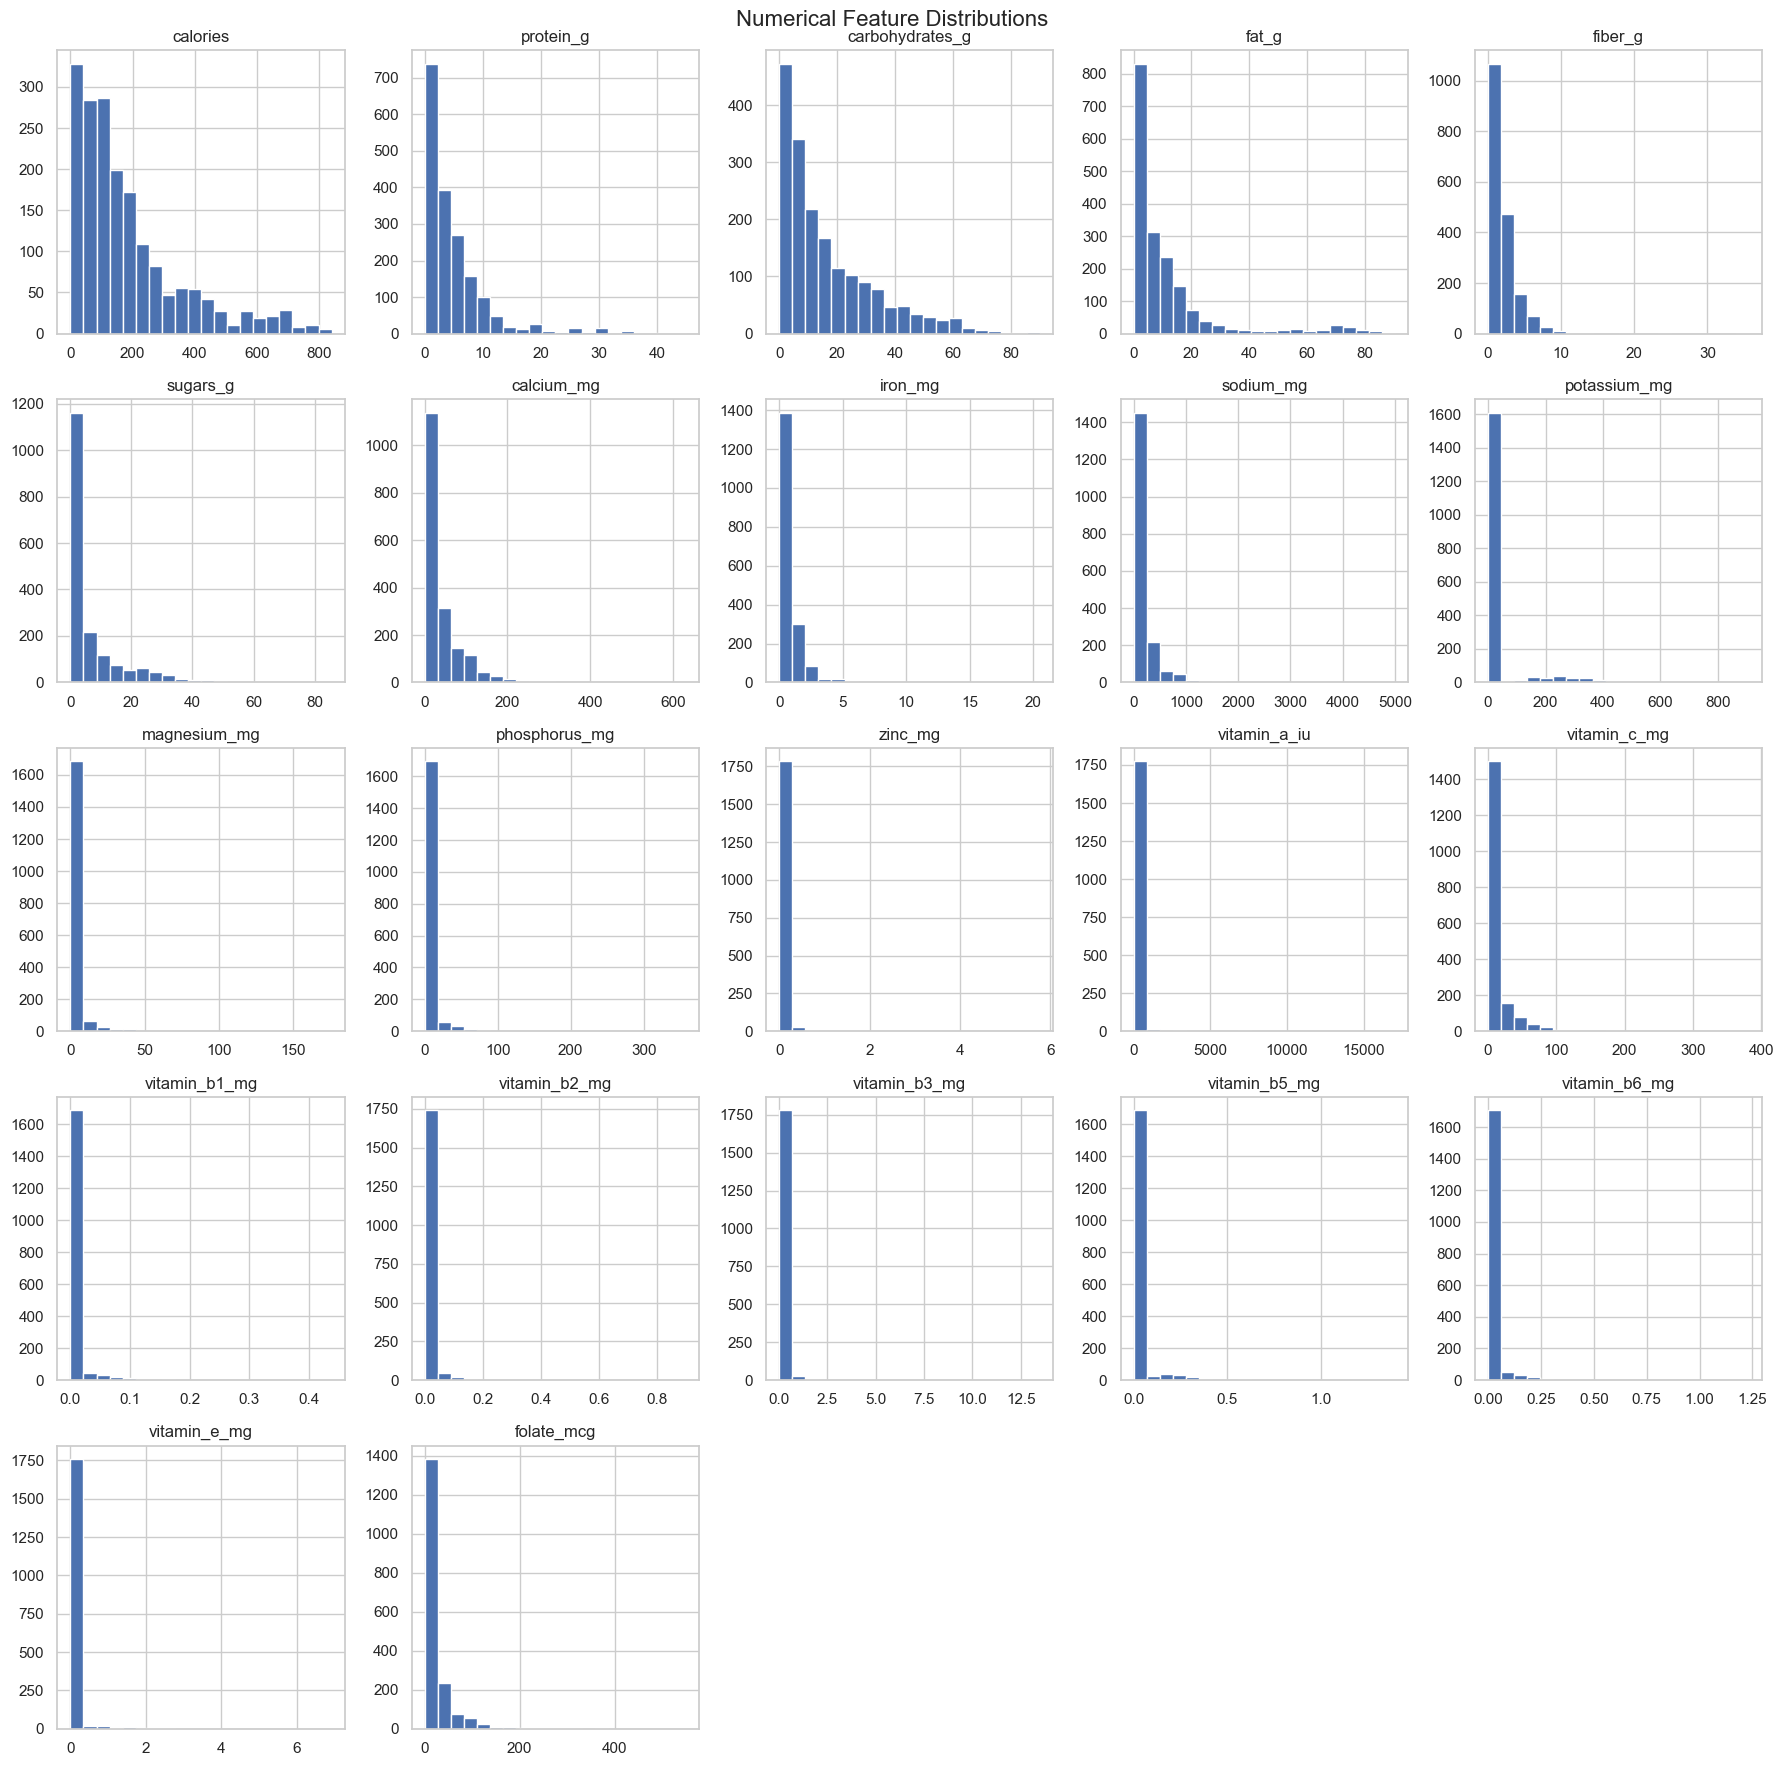

In [4]:
# 2.3 Numerical feature distributions
numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols].hist(figsize=(18,18), bins=20)
plt.suptitle('Numerical Feature Distributions', fontsize=16)
plt.tight_layout()
plt.show()

**Observation:** The nutritional variables have different ranges and distributions. This supports the use of feature scaling for distance-based and margin-based classifiers.

In [5]:
# 2.4 Categorical distributions
print('Food Category Counts:')
print(df['category'].value_counts())

print('\nFood Name Count:', df['food_name'].nunique())

Food Category Counts:
category
Indian Food             1014
Vegetable                160
Condiment                115
Fruit                     82
General                   66
Beverage                  52
Grain                     49
Meal/Processed            28
Protein/Meat              27
Dairy                     26
Dessert                   26
Meal/Meat                 19
Snack/Processed           15
Meal/Pasta                14
Nut                       13
Meal/Vegetarian           10
Legume                     9
Meal/Vegetable             8
Protein/Fish               8
Grain/Processed            7
Meal/Seafood               6
Protein/Vegetarian         6
Condiment/Dairy            5
Meal/Grain                 5
Protein/Seafood            5
Protein                    4
Meal/Protein               4
Meal/Soup                  4
Vegetable/Processed        3
Beverage/Dairy-Alt         3
Meal/Fish                  3
Meal/Legume                3
Beverage/Dairy             2
Meal/Rice   

**Observation:** `food_name` is a high-cardinality identifier-like text field, so it is not used as a predictor. The original `category` is converted into the classification target `category_group`.

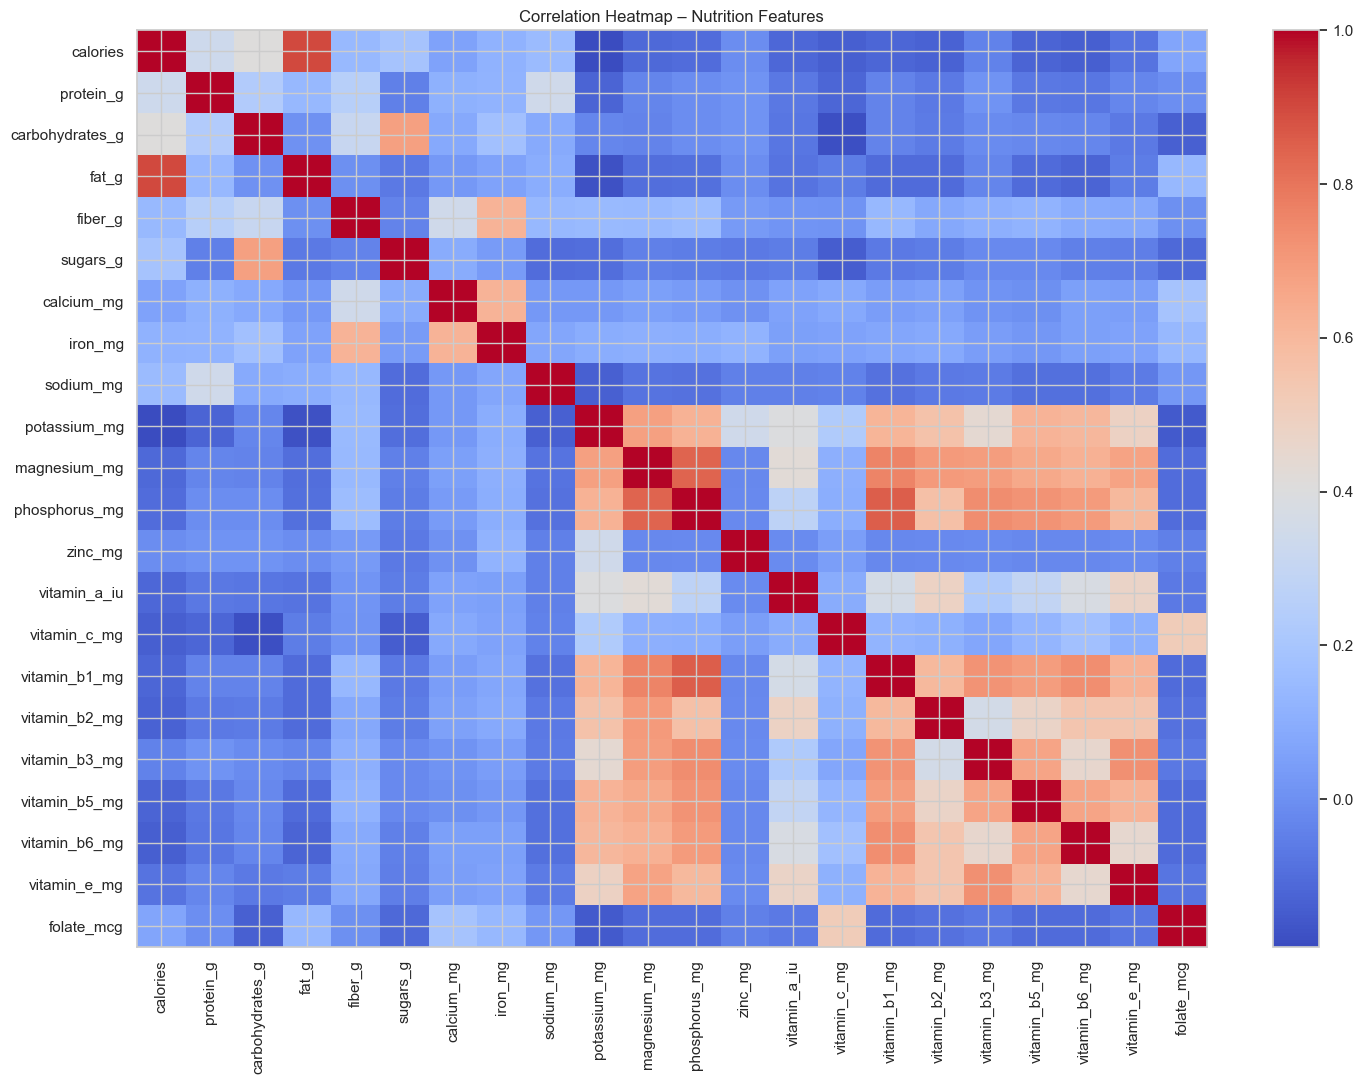

In [6]:
# 2.5 Correlation heatmap
plt.figure(figsize=(15,11))
corr = df[numeric_cols].corr()
plt.imshow(corr, cmap='coolwarm', aspect='auto')
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('Correlation Heatmap – Nutrition Features')
plt.tight_layout()
plt.show()

**Observation:** The heatmap shows relationships among calories, macronutrients and micronutrients. Strong correlations can indicate redundant information, while weaker relationships may provide additional classification information.

<Figure size 1000x500 with 0 Axes>

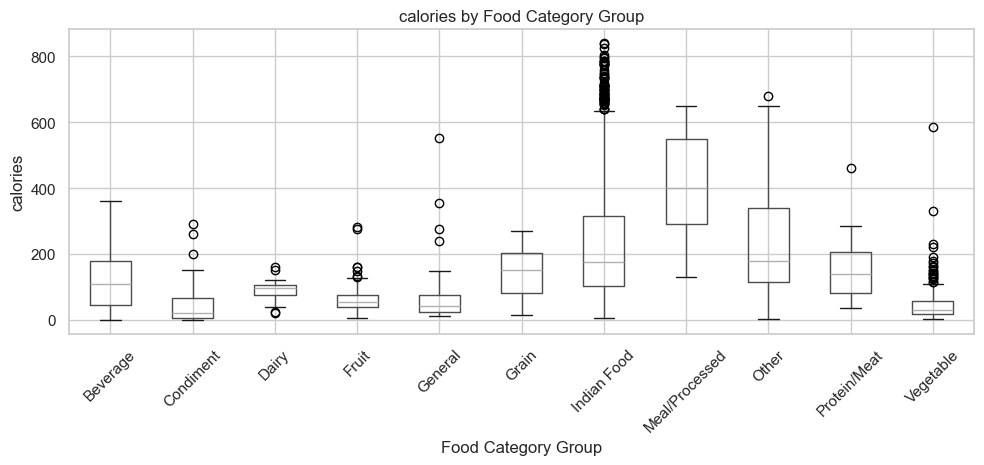

<Figure size 1000x500 with 0 Axes>

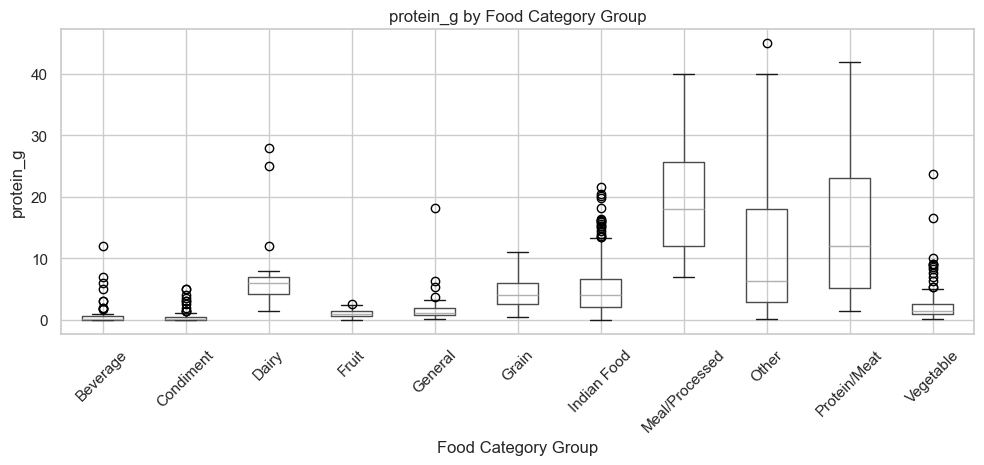

<Figure size 1000x500 with 0 Axes>

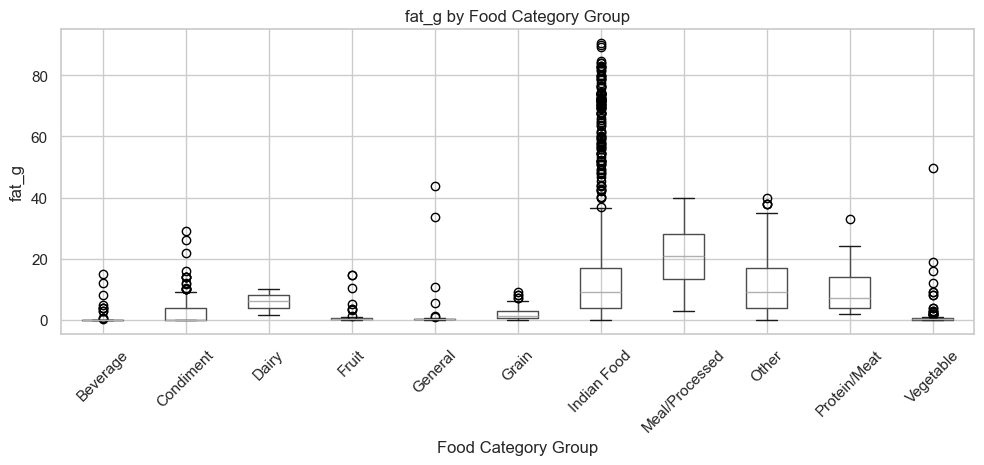

In [7]:
# 2.6 Feature-target relationship plots
for col in ['calories', 'protein_g', 'fat_g']:
    plt.figure(figsize=(10,5))
    df.boxplot(column=col, by='category_group', rot=45, figsize=(10,5))
    plt.title(f'{col} by Food Category Group')
    plt.suptitle('')
    plt.xlabel('Food Category Group')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

**Observation:** The feature-target boxplots compare the distribution of important nutritional variables across food category groups. Differences in their central values and spreads indicate why these measurements may help distinguish food categories.

In [8]:
# 3.1 Missing values and duplicates
print('Total Missing Values:', df.isnull().sum().sum())
print('Duplicate Rows:', df.duplicated().sum())

# Outlier count using the IQR rule
outlier_counts = {}
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outlier_counts[col] = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()

print('\nOutlier Counts:')
print(pd.Series(outlier_counts).sort_values(ascending=False))

Total Missing Values: 0
Duplicate Rows: 0

Outlier Counts:
vitamin_c_mg       230
sugars_g           226
potassium_mg       210
folate_mcg         169
sodium_mg          156
fat_g              152
phosphorus_mg      145
vitamin_b3_mg      144
vitamin_b2_mg      144
magnesium_mg       143
vitamin_b1_mg      143
vitamin_b6_mg      143
vitamin_b5_mg      139
vitamin_a_iu       128
vitamin_e_mg       124
calories           124
protein_g          112
calcium_mg         106
fiber_g            102
iron_mg             75
zinc_mg             66
carbohydrates_g     59
dtype: int64


**Observation:** Missing values and duplicates are checked before modeling. The IQR counts identify variables with unusually large or small observations. Outlier treatment is applied using training-set statistics only.

In [9]:
# 4.1 Feature engineering
df['total_macros_g'] = (
    df['protein_g'] + df['carbohydrates_g'] + df['fat_g']
)

df['fat_carb_ratio'] = df['fat_g'] / (df['carbohydrates_g'] + 1)
df['protein_carb_ratio'] = df['protein_g'] / (df['carbohydrates_g'] + 1)

print(df[['total_macros_g', 'fat_carb_ratio', 'protein_carb_ratio']].describe().T)

                     count       mean        std  min        25%        50%  \
total_macros_g      1818.0  32.834664  25.853614  0.0  12.917500  25.675000   
fat_carb_ratio      1818.0   1.598550   3.608075  0.0   0.051037   0.344461   
protein_carb_ratio  1818.0   0.796023   2.743388  0.0   0.109115   0.210035   

                          75%         max  
total_macros_g      47.737500  128.000000  
fat_carb_ratio       1.014579   37.388626  
protein_carb_ratio   0.441644   42.000000  


In [10]:
# 4.2 Prepare features and target
X = df.drop(columns=['category', 'category_group', 'food_name']).select_dtypes(include=np.number)
y = df['category_group']

print('Feature Matrix Shape:', X.shape)
print('Target Shape:', y.shape)

Feature Matrix Shape: (1818, 25)
Target Shape: (1818,)


In [11]:
# 4.3 Stratified 80:20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training samples:', X_train.shape[0])
print('Testing samples:', X_test.shape[0])

Training samples: 1454
Testing samples: 364


In [12]:
# 4.4 Missing values and outlier treatment using training data only
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

X_train = X_train.clip(lower=lower, upper=upper, axis=1)
X_test = X_test.clip(lower=lower, upper=upper, axis=1)

print('Training missing values:', X_train.isnull().sum().sum())
print('Testing missing values:', X_test.isnull().sum().sum())

Training missing values: 0
Testing missing values: 0


In [13]:
# 4.5 Standard scaling fitted only on the training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Scaled training shape:', X_train_scaled.shape)
print('Scaled testing shape:', X_test_scaled.shape)

Scaled training shape: (1454, 25)
Scaled testing shape: (364, 25)


In [14]:
# Classification Models 1–2

# 1. Logistic Regression
log_model = LogisticRegression(max_iter=2000, random_state=42)
log_model.fit(X_train_scaled, y_train)
log_pred = log_model.predict(X_test_scaled)

log_accuracy = accuracy_score(y_test, log_pred)
log_f1 = f1_score(y_test, log_pred, average='weighted')

print('1. Logistic Regression')
print(f'Accuracy   : {log_accuracy:.4f}')
print(f'Weighted F1: {log_f1:.4f}')

# 2. K-Nearest Neighbors
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_pred = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, knn_pred)
knn_f1 = f1_score(y_test, knn_pred, average='weighted')

print('\n2. K-Nearest Neighbors')
print(f'Accuracy   : {knn_accuracy:.4f}')
print(f'Weighted F1: {knn_f1:.4f}')


1. Logistic Regression
Accuracy   : 0.8516
Weighted F1: 0.8486

2. K-Nearest Neighbors
Accuracy   : 0.8324
Weighted F1: 0.8267


In [15]:
# Classification Models 3–4

# 3. Gaussian Naive Bayes
gnb_model = GaussianNB()
gnb_model.fit(X_train_scaled, y_train)
gnb_pred = gnb_model.predict(X_test_scaled)

gnb_accuracy = accuracy_score(y_test, gnb_pred)
gnb_f1 = f1_score(y_test, gnb_pred, average='weighted')

print('3. Gaussian Naive Bayes')
print(f'Accuracy   : {gnb_accuracy:.4f}')
print(f'Weighted F1: {gnb_f1:.4f}')

# 4. Decision Tree Classifier
dt_model = DecisionTreeClassifier(max_depth=6, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred, average='weighted')

print('\n4. Decision Tree Classifier')
print(f'Accuracy   : {dt_accuracy:.4f}')
print(f'Weighted F1: {dt_f1:.4f}')


3. Gaussian Naive Bayes
Accuracy   : 0.8269
Weighted F1: 0.8255

4. Decision Tree Classifier
Accuracy   : 0.8791
Weighted F1: 0.8681


In [16]:
# Classification Model 5

# 5. Support Vector Classifier
svc_model = SVC(C=1.0, kernel='rbf', random_state=42)
svc_model.fit(X_train_scaled, y_train)
svc_pred = svc_model.predict(X_test_scaled)

svc_accuracy = accuracy_score(y_test, svc_pred)
svc_f1 = f1_score(y_test, svc_pred, average='weighted')

print('5. Support Vector Classifier')
print(f'Accuracy   : {svc_accuracy:.4f}')
print(f'Weighted F1: {svc_f1:.4f}')


5. Support Vector Classifier
Accuracy   : 0.8242
Weighted F1: 0.8185


Classification Model Comparison:


,Algorithm,Accuracy,Weighted F1
0,1. Logistic Regression,0.8516,0.8486
1,2. KNN,0.8324,0.8267
2,3. Gaussian Naive Bayes,0.8269,0.8255
3,4. Decision Tree,0.8791,0.8681
4,5. SVC,0.8242,0.8185


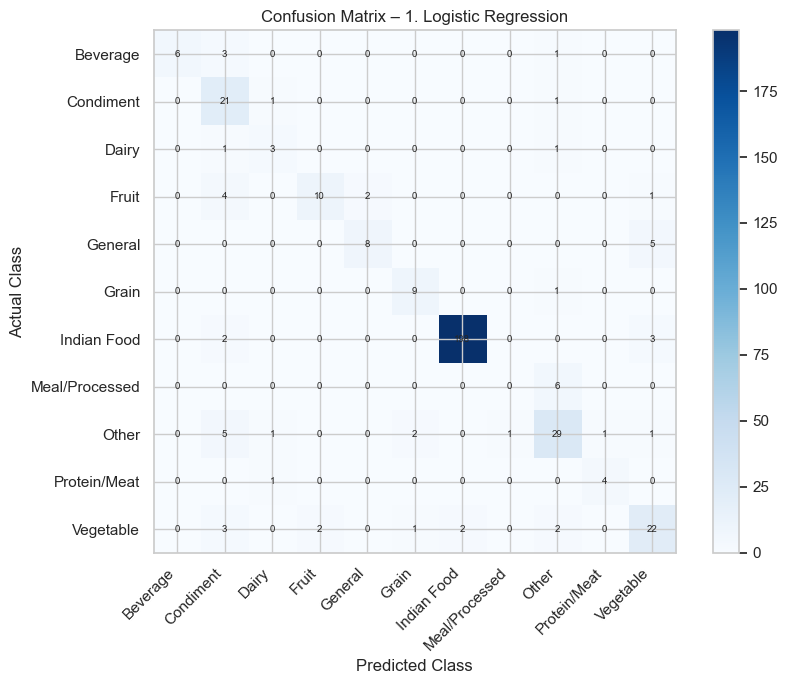

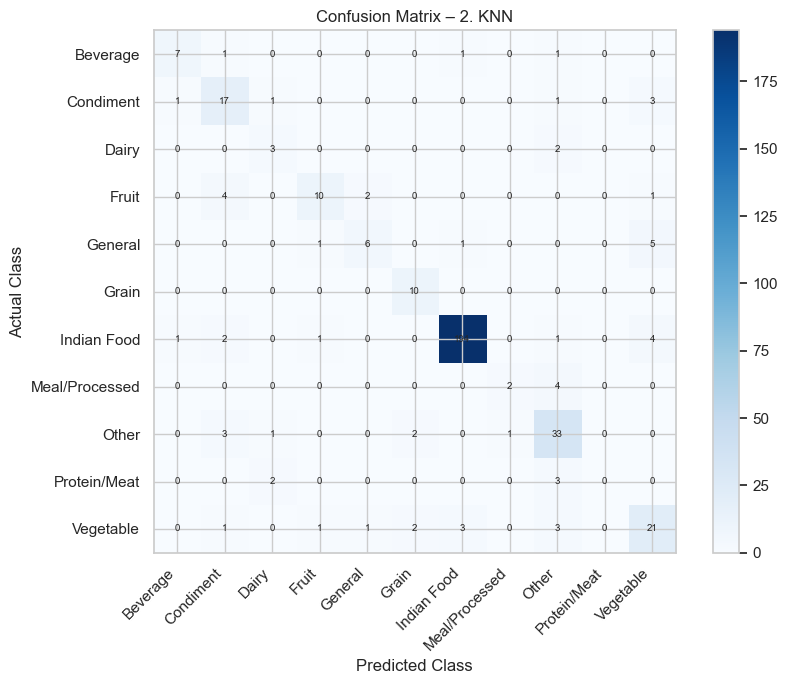

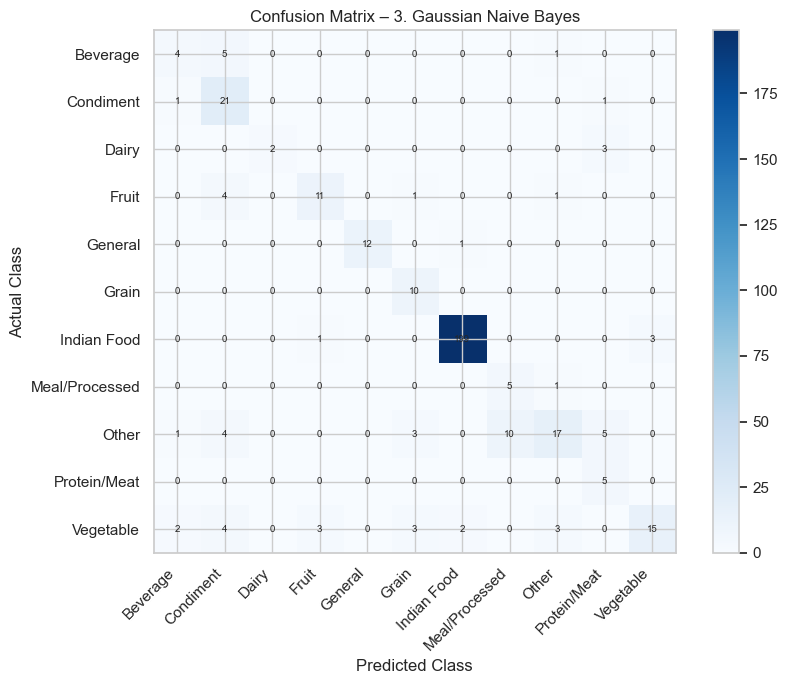

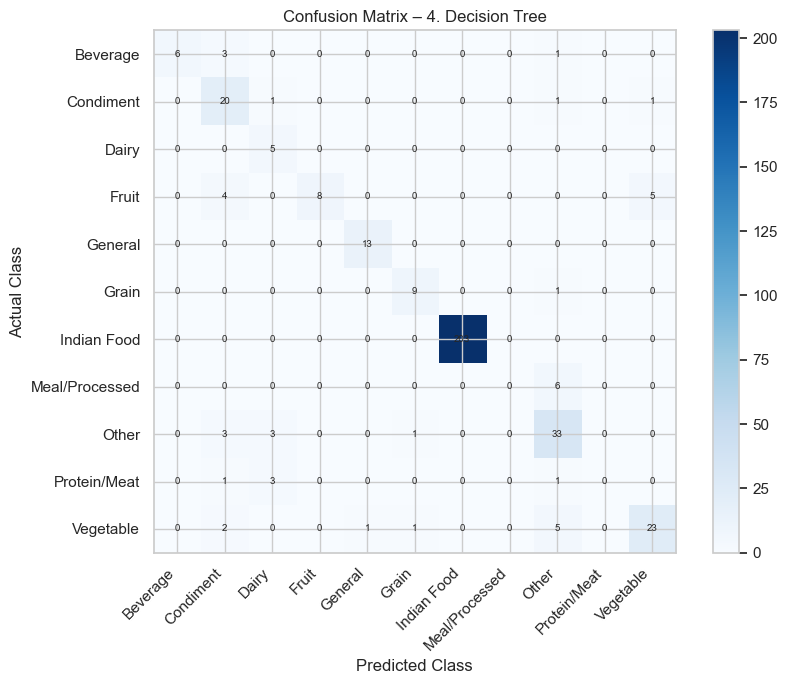

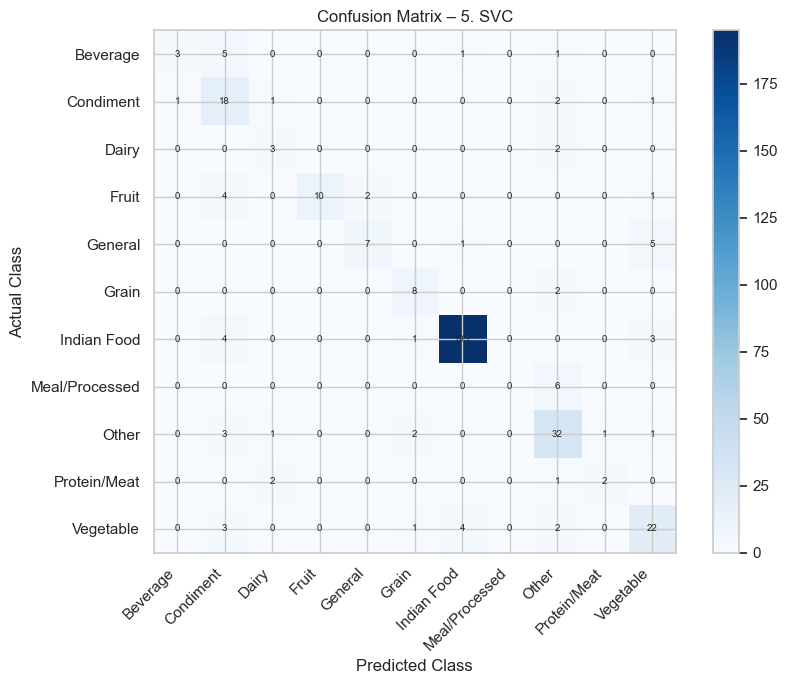

Sorted Classification Comparison:


,Algorithm,Accuracy,Weighted F1
0,4. Decision Tree,0.8791,0.8681
1,1. Logistic Regression,0.8516,0.8486
2,2. KNN,0.8324,0.8267
3,3. Gaussian Naive Bayes,0.8269,0.8255
4,5. SVC,0.8242,0.8185


In [17]:
# Final Classification Evaluation
predictions = {
    '1. Logistic Regression': log_pred,
    '2. KNN': knn_pred,
    '3. Gaussian Naive Bayes': gnb_pred,
    '4. Decision Tree': dt_pred,
    '5. SVC': svc_pred
}

comparison = []

for name, pred in predictions.items():
    accuracy = accuracy_score(y_test, pred)
    weighted_f1 = f1_score(y_test, pred, average='weighted')

    comparison.append({
        'Algorithm': name,
        'Accuracy': round(accuracy, 4),
        'Weighted F1': round(weighted_f1, 4)
    })

comparison_table = pd.DataFrame(comparison)

print('Classification Model Comparison:')
display(comparison_table)

# Confusion matrices for all five classifiers
class_labels = sorted(y_test.unique())

for name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred, labels=class_labels)

    plt.figure(figsize=(9, 7))
    plt.imshow(cm, interpolation='nearest', cmap='Blues')
    plt.colorbar()
    plt.xticks(
        range(len(class_labels)),
        class_labels,
        rotation=45,
        ha='right'
    )
    plt.yticks(range(len(class_labels)), class_labels)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j, i, cm[i, j],
                ha='center',
                va='center',
                fontsize=7
            )

    plt.title(f'Confusion Matrix – {name}')
    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.tight_layout()
    plt.show()

# Sorted comparison for interpretation
classification_comparison = comparison_table.sort_values(
    'Weighted F1',
    ascending=False
).reset_index(drop=True)

print('Sorted Classification Comparison:')
display(classification_comparison)


**Observation:** Accuracy measures the proportion of correctly classified food records, while weighted F1 balances precision and recall while accounting for class sizes. The confusion matrices show which food category groups are correctly classified and where misclassification occurs.

In [18]:
# 6.1 Preliminary comparison
comparison_table = comparison_table.sort_values(
    'Weighted F1', ascending=False
).reset_index(drop=True)

display(comparison_table)

,Algorithm,Accuracy,Weighted F1
0,4. Decision Tree,0.8791,0.8681
1,1. Logistic Regression,0.8516,0.8486
2,2. KNN,0.8324,0.8267
3,3. Gaussian Naive Bayes,0.8269,0.8255
4,5. SVC,0.8242,0.8185


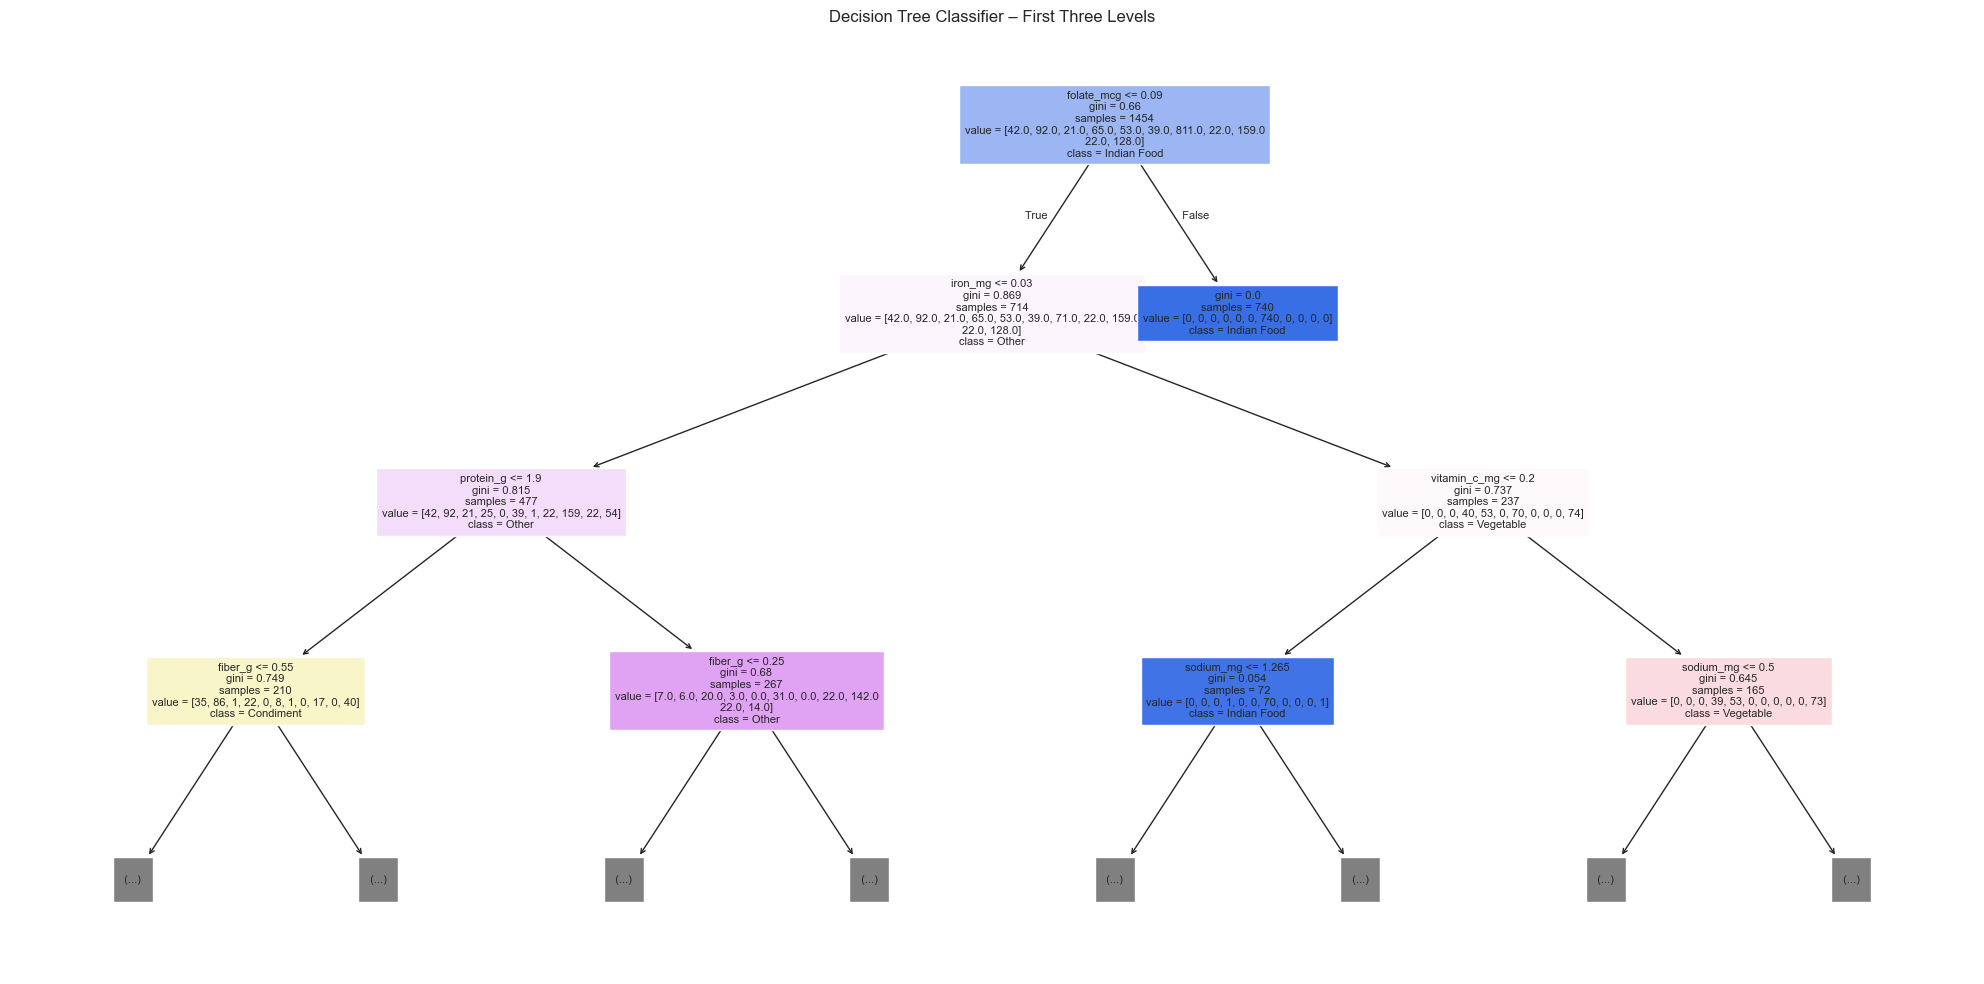

In [19]:
# Visualise the required Decision Tree model
plt.figure(figsize=(20,10))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=sorted(y.unique()),
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title('Decision Tree Classifier – First Three Levels')
plt.tight_layout()
plt.show()